# Build an Evidence Pack for an AI Answer

Turn an AI answer and its located citations into one PDF: a cover with source fingerprints, an entry with an evidence image for every claim, unverified claims flagged, and the highlighted source pages.

Companion notebook for the article [Build an Evidence Pack for an AI Answer](https://pymupdf.io/blog/build-an-evidence-pack-for-an-ai-answer) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [2]:
import pymupdf
doc = pymupdf.open()
sections = [
 ("Acme Corporation Annual Report 2025", None),
 ("1. Financial highlights", "Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. Operating margin improved to 18.4%, compared with 16.9% in the prior year. The company returned $350 million to shareholders through dividends and share repurchases."),
 ("2. Outlook", "Management expects revenue growth of 8% to 10% in fiscal 2026, with continued investment in cloud infrastructure and data centers in Europe and Asia. Capital expenditure is expected to reach $600 million."),
 ("3. Risk factors", "The company depends on a small number of large customers. In fiscal 2025, the three largest customers accounted for 31% of net revenue. The loss of any of these customers could materially affect results."),
 ("4. Supply chain", "Supply chain disruptions in 2024 delayed shipments of hardware appliances by up to six weeks. These delays did not recur in 2025, and inventory levels returned to normal by the second quarter."),
]
page = doc.new_page(); y = 72
for i,(h,body) in enumerate(sections):
    if i == 3:
        page = doc.new_page(); y = 72
    size = 18 if i == 0 else 14
    page.insert_text((72, y+size), h, fontsize=size, fontname="hebo"); y += size + 14
    if body:
        r = pymupdf.Rect(72, y, 400, y+200)
        rc = page.insert_textbox(r, body, fontsize=11, fontname="helv")
        y += 200 - rc + 18
doc.save("acme_report.pdf")

## Grounding helpers
`locate()` comes from the first article in the series, [Cite Claude's Answers at the Exact Spot in the PDF](https://pymupdf.io/blog/cite-claude-answers-at-the-exact-spot-in-the-pdf). It is also part of [the PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill).

In [ ]:
import re
import pymupdf


def locate(page, cited_text):
    """Return the quads of cited_text on a page, or [] if not found."""
    text = " ".join(cited_text.split())          # collapse whitespace and line breaks
    quads = page.search_for(text, quads=True)    # case-insensitive, joins hyphenated words
    if quads:
        return quads
    return _locate_by_words(page, text)          # fallback for small differences


def _norm(word):
    return re.sub(r"[^\w%$.]", "", word).lower().rstrip(".")


def _locate_by_words(page, text):
    """Match the quote word by word, ignoring punctuation, case and hyphenation."""
    target = [_norm(w) for w in text.split() if _norm(w)]
    words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
    tokens = [(_norm(w[4]), pymupdf.Rect(w[:4])) for w in words]
    tokens = [t for t in tokens if t[0]]
    n = len(target)
    for i in range(len(tokens) - n + 1):
        if all(tokens[i + k][0] == target[k] for k in range(n)):
            return [r.quad for _, r in tokens[i:i + n]]
    return []


def ground_citations(response, docs):
    """Map each page_location citation in a Claude response to quads on the page.

    response: the Message returned by client.messages.create()
    docs: the PyMuPDF documents, in the order they were sent to Claude
    """
    results = []
    for block in response.content:
        if block.type != "text" or not getattr(block, "citations", None):
            continue
        for cit in block.citations:
            if cit.type != "page_location":
                continue
            doc = docs[cit.document_index]
            # Claude's page numbers are 1-based; end_page_number is exclusive
            for pno in range(cit.start_page_number - 1, cit.end_page_number - 1):
                quads = locate(doc[pno], cit.cited_text)
                if quads:
                    results.append({"claim": block.text, "cited_text": cit.cited_text,
                                    "doc": cit.document_index, "page": pno, "quads": quads})
                    break
            else:
                results.append({"claim": block.text, "cited_text": cit.cited_text,
                                "doc": cit.document_index, "page": None, "quads": []})
    return results


def snippet(docs, r, margin=24, dpi=150, full_width=False):
    """Render the cited region, highlighted, with some surrounding context.

    The document itself is left unchanged.
    """
    page = docs[r["doc"]][r["page"]]
    box = pymupdf.Rect()
    for q in r["quads"]:
        box |= q.rect
    clip = box + (-margin, -margin, margin, margin)
    for block in page.get_text("dict")["blocks"]:          # extend to whole lines
        for line in block.get("lines", []):
            if clip.intersects(line["bbox"]):
                clip |= line["bbox"]
    clip += (-4, -4, 4, 4)
    if full_width:
        clip.x0, clip.x1 = page.rect.x0, page.rect.x1
    clip &= page.rect
    annot = page.add_highlight_annot(r["quads"])            # temporary highlight
    pix = page.get_pixmap(clip=clip, dpi=dpi)
    page.delete_annot(annot)
    return pix


def highlight(docs, results):
    """Add a highlight annotation per located citation, with the claim as its note."""
    for r in results:
        if not r["quads"]:
            continue
        page = docs[r["doc"]][r["page"]]
        annot = page.add_highlight_annot(r["quads"])
        annot.set_info(content=r["claim"])
        annot.update()

## What goes in the pack
- A cover with the question, how many citations were located, each source file with its SHA-256 fingerprint, and the time the pack was created.
- One entry per claim: the claim, the quoted text, its status, an image of the evidence with the surrounding lines, and the source page.
- Claims whose citation could not be found, marked for review instead of left out.
- The cited source pages at the end, with the evidence highlighted. Clicking an evidence image jumps to its page.

## Starting point

We need the located citations from the first article: for each claim, the cited text, the document, the page and the quads. If you use [the PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill), `ground_citations()` and `snippet()` are in its helper script.

In [4]:
import pymupdf

path = "acme_report.pdf"
doc = pymupdf.open(path)
# With a real API key, use Claude with citations enabled, as in the first article:
# response = client.messages.create(...)
# Here we simulate a response with four claims; the last cites text that is not in the report.
from types import SimpleNamespace as NS

def cit(text, start, end):
    return NS(type="page_location", cited_text=text, document_index=0,
              start_page_number=start, end_page_number=end)

response = NS(content=[
    NS(type="text", text="Acme's revenue grew 12% to $4.1 billion in 2025.",
       citations=[cit("Net revenue increased 12% to $4.1 billion, driven by growth in the enterprise software segment. ", 1, 2)]),
    NS(type="text", text="It expects revenue growth of 8% to 10% in 2026.",
       citations=[cit("Management expects revenue growth of 8% to 10% in fiscal 2026", 1, 2)]),
    NS(type="text", text="Three customers account for 31% of revenue.",
       citations=[cit("In fiscal 2025, the three largest customers accounted for 31% of net revenue.", 2, 3)]),
    NS(type="text", text="Revenue in Asia doubled.",
       citations=[cit("Revenue in Asia doubled compared with the prior year.", 1, 3)]),
])
results = ground_citations(response, [doc])

## The code

In [ ]:
import hashlib
import html
from datetime import datetime, timezone

import pymupdf



def build_evidence_pack(question, results, docs, paths, out_path):
    """Write one PDF that shows the evidence for every claim in an answer.

    results: located citations, as returned by ground_citations()
    docs, paths: the source documents and their file paths, in the same order
    """
    pack = pymupdf.open()
    width, height, margin = 595, 842, 50 # A4 in points
    page, y = None, height

    def new_page():
        nonlocal page, y
        page, y = pack.new_page(width=width, height=height), margin

    def write(html_text, box_height=400):
        """Write HTML at the cursor and move the cursor below it."""
        nonlocal y
        rect = pymupdf.Rect(margin, y, width - margin, y + box_height)
        spare, _ = page.insert_htmlbox(rect, html_text)
        y += box_height - spare + 6

    # Cover: question, sources with fingerprints, time of creation
    new_page()
    located = sum(1 for r in results if r["quads"])
    write(f"<h2>Evidence pack</h2><p><b>Question:</b> {html.escape(question)}</p>"
          f"<p>{located} of {len(results)} citations located in the source.</p>")
    for path in paths:
        digest = hashlib.sha256(open(path, "rb").read()).hexdigest()
        write(f"<p style='font-size:9px'>Source: {html.escape(path)}<br>SHA-256: <span style='font-family:monospace'>{digest}</span></p>")
    created = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    write(f"<p style='font-size:9px'>Created {created}</p>")

    # Render evidence images before highlighting, then add the highlighted source pages
    images = [snippet(docs, r) if r["quads"] else None for r in results]
    highlight(docs, results)
    appended = {} # (doc, page) -> page in the pack

    # One entry per claim
    links = []
    for n, (r, pix) in enumerate(zip(results, images), start=1):
        needed = 120 + (pix.height * 72 / 150 if pix else 0)
        if y + needed > height - margin:
            new_page()
        found = r["quads"] != []
        status = "Found" if found else "<span style='color:#c00'>NOT FOUND, review needed</span>"
        write(f"<p><b>Claim {n}.</b> {html.escape(r['claim'])}<br>"
              f"<span style='font-size:9px'>Cited text: “{html.escape(r['cited_text'].strip())}”<br>"
              f"Status: {status}</span></p>")
        if found:
            scale = min(1, (width - 2 * margin) / (pix.width * 72 / 150))
            w, h = pix.width * 72 / 150 * scale, pix.height * 72 / 150 * scale
            img_rect = pymupdf.Rect(margin, y, margin + w, y + h)
            page.insert_image(img_rect, pixmap=pix)
            y += h + 4
            ref = f"{paths[r['doc']]}, page {r['page'] + 1}"
            write(f"<p style='font-size:9px'>{html.escape(ref)} (click the image to open the highlighted page)</p>", 30)
            links.append((page.number, img_rect, (r["doc"], r["page"])))
        y += 8

    # Append each cited source page once, with its highlights, and link to it
    for doc_index, pno in sorted({key for _, _, key in links}):
        pack.insert_pdf(docs[doc_index], from_page=pno, to_page=pno)
        appended[(doc_index, pno)] = pack.page_count - 1
    for page_number, rect, key in links:
        pack[page_number].insert_link({"kind": pymupdf.LINK_GOTO, "from": rect,
                                       "page": appended[key], "to": pymupdf.Point(0, 0)})

    pack.save(out_path, garbage=3, deflate=True)
    return out_path

## How it works
- **Text layout.** `Page.insert_htmlbox()` writes simple HTML into a rectangle and returns the unused height, so the `write()` helper can move a cursor down the page. A new page starts when the next entry would not fit.
- **Fingerprints.** The SHA-256 of each source file ties the pack to the exact version of the document. The hash is set in a monospace font: in a proportional font, letter pairs such as "ff" can be joined into ligatures, and the hash would no longer copy correctly.
- **Evidence images.** `snippet()` renders each cited region with a temporary highlight and the surrounding lines, and leaves the document unchanged.
- **Status.** A citation that was not found is listed in red as "NOT FOUND, review needed". An evidence pack that silently drops unverified claims would defeat its purpose.
- **Source pages and links.** After the images are rendered, `highlight()` adds highlight annotations to the documents in memory. `Document.insert_pdf()` copies each cited page into the pack once, highlights included, and `Page.insert_link()` turns each evidence image into a link to that page.

## Build the pack

In [6]:
build_evidence_pack(
    "How did Acme perform in 2025, and what are the risks?",
    results, [doc], [path], "evidence_pack.pdf",
)

'evidence_pack.pdf'

4 pages


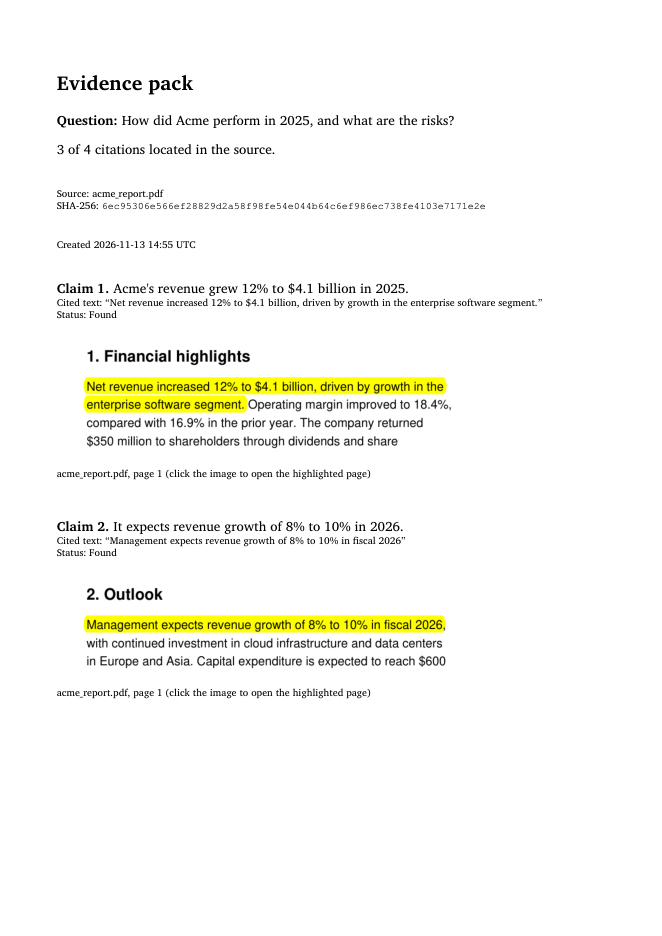

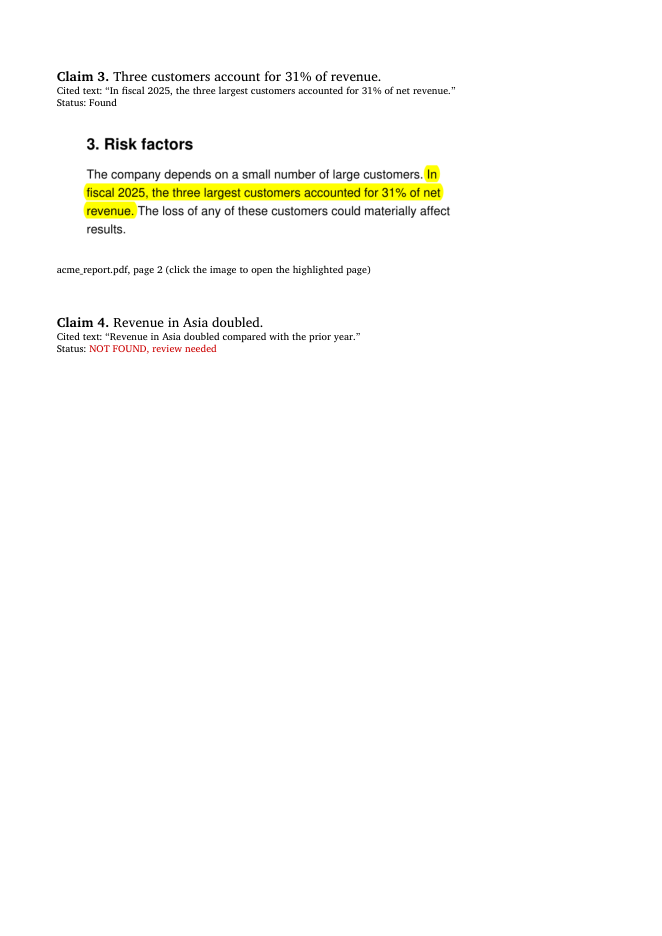

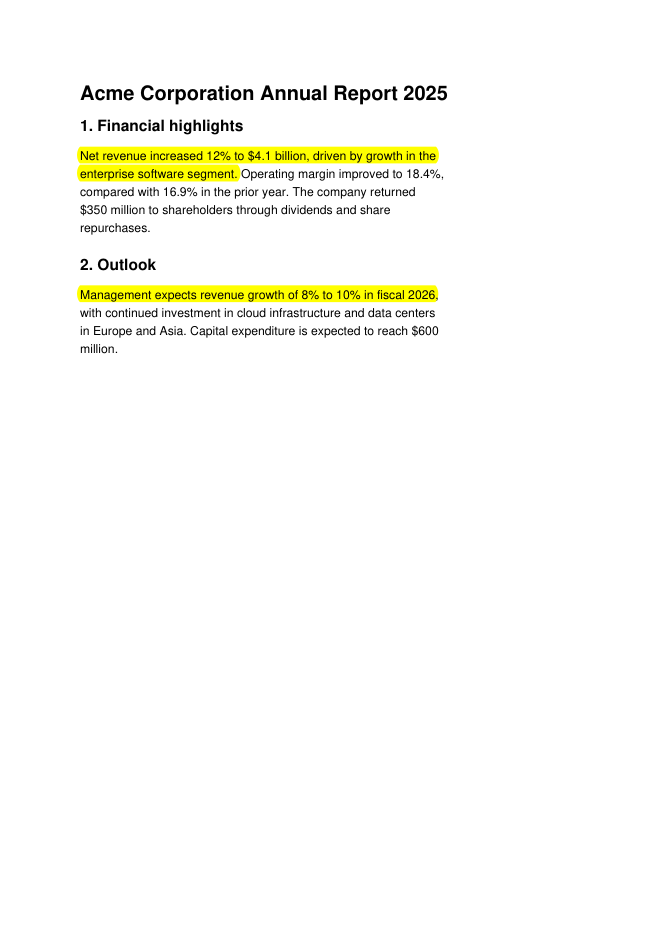

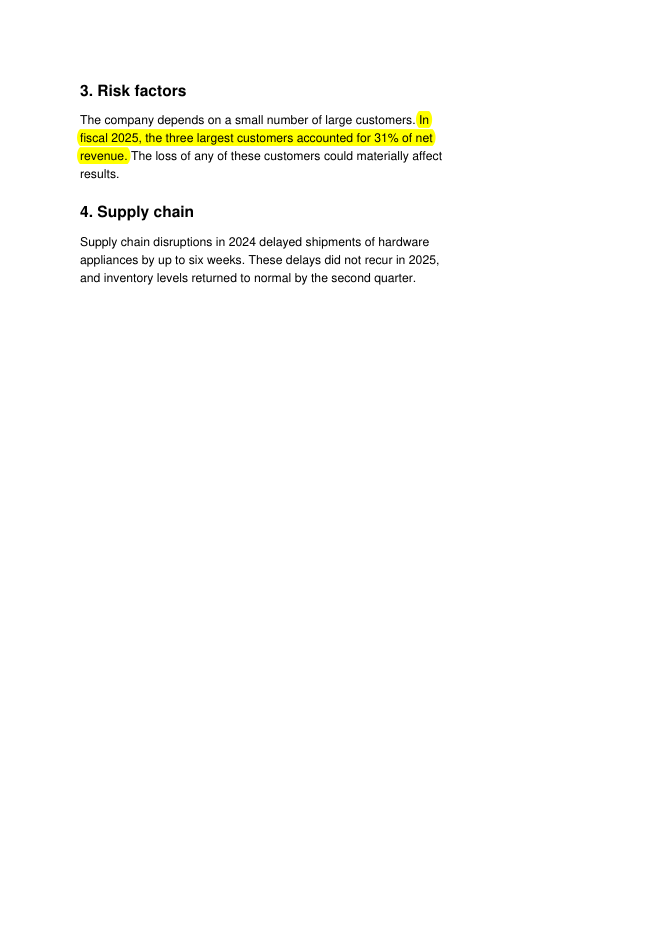

In [7]:
from IPython.display import Image, display
pack = pymupdf.open("evidence_pack.pdf")
print(pack.page_count, "pages")
for page in pack:
    display(Image(page.get_pixmap(dpi=80).tobytes("png")))

The sample answer has four claims. Three were located; the fourth, "Revenue in Asia doubled", cites text that is not in the report, so the pack flags it for review.

## Variations
- **Several documents.** Pass all documents and paths in the order they were sent to the model. The cover lists each source with its own fingerprint.
- **Tables and figures.** Use `snippet(docs, r, full_width=True)` when the content next to a passage gives it meaning.
- **The full answer.** Add the model's complete answer to the cover, so the pack records what the user saw.

## Limits to know
- `highlight()` adds annotations to the source documents in memory. Do not save those documents over the originals.
- The timestamp comes from the machine that builds the pack. It is a record, not a trusted timestamp.
- The pack is only as good as the citations: a claim without any citation does not appear in it. A later article in this series covers catching uncited and hallucinated citations.

## Next steps

- Read the full article: https://pymupdf.io/blog/build-an-evidence-pack-for-an-ai-answer
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding